# LLM Fine Tuning · Lesson 3 · Prepare the data

Lesson 2 chose the model, Qwen2.5-1.5B-Instruct. This lab prepares the data it will be trained on in lesson 4: questions
in plain English, the table they are about, and the SQL that answers them. The dataset is
[sql-create-context](https://huggingface.co/datasets/b-mc2/sql-create-context) (CC BY 4.0, built from WikiSQL and Spider).

Six questions are asked of the data, and each is answered by a measurement:

1. **Is every label right?** Run every gold SQL query against its table.
2. **Are there duplicates or contradictions?**
3. **Will the split tell the truth?** Measure leakage between training and test.
4. **How long are the examples?** Token lengths, and the maximum length to train with.
5. **What does the model see?** The examples in the model's chat template.
6. **Where is the loss computed?** On the answer only, and why.

The lab ends by saving clean training, validation and test files for lesson 4.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all (about five minutes).
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/1-decide/03-prepare-the-data).

## 0. Install and load the data

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 accelerate==1.6.0

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import collections
import json
import random
import re
import sqlite3
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from transformers import AutoModelForCausalLM, AutoTokenizer

%config InlineBackend.figure_formats = ['svg']
SEED = 42

# Pinned to one commit of the dataset, so the counts below cannot change under the lesson.
URL = ("https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/"
       "9d80a6a118b838d9defc3798d659a54a2ac2ff37/sql_create_context_v4.json")
rows = json.load(urllib.request.urlopen(URL))
data = pd.DataFrame(rows)
print(f"{len(data):,} examples")
print(data.iloc[0].to_dict())

78,577 examples
{'question': 'How many heads of the departments are older than 56 ?', 'context': 'CREATE TABLE head (age INTEGER)', 'answer': 'SELECT COUNT(*) FROM head WHERE age > 56'}


## 1. Is every label right?

A label here is the gold SQL query. For this task there is a check that costs nothing: create the table from the
`CREATE TABLE` statement in an empty SQLite database and run the query. A query that does not run cannot be a
correct answer, and a model trained on it learns to write SQL that does not run.

In [3]:
def runs(context, sql):
    """Return None if the query runs against the schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]
broken = data[data["error"].notna()]
print(f"{len(broken):,} of {len(data):,} gold queries fail ({len(broken) / len(data):.1%})")


def kind(err):
    if "syntax error" in err:
        return "syntax error"
    if "no such function" in err:
        return "unknown function"
    if "no such column" in err:
        return "unknown column"
    if "already exists" in err:
        return "schema defines a table twice"
    return "other"


print(broken["error"].map(kind).value_counts().to_string())
print()
for _, r in broken.sample(6, random_state=1).iterrows():
    print(f"{r['error'][:45]:45s} | {r['answer'][:110]}")

1,667 of 78,577 gold queries fail (2.1%)
error
syntax error                    1221
unknown column                   185
schema defines a table twice     137
unknown function                  90
other                             34

near "AS": syntax error                       | SELECT MAX(10 AS _c_pts) FROM table_25887826_17 WHERE total_pts = 39
near "OFFSET": syntax error                   | SELECT COUNT(election) FROM table_name_14 WHERE inhabitants < 16 OFFSET 170
near "OFFSET": syntax error                   | SELECT artist FROM table_name_87 WHERE peak_position < 2 AND sales > 200 OFFSET 000
near "$_per_capita_": syntax error            | SELECT COUNT(tourism_receipts__2011___us) AS $_per_capita_ FROM table_18524_6 WHERE tourism_receipts__2003___a
near "OFFSET": syntax error                   | SELECT MAX(elevation__ft_) FROM table_name_40 WHERE type = "stratovolcano" AND name = "goat rocks" AND elevati
near "AS": syntax error                       | SELECT AVG(1 AS st_prize__) 

## 2. Are there duplicates or contradictions?

An exact duplicate is counted twice in training and, if it lands on both sides of the split, scores itself. A
contradiction, the same question about the same table with two different answers, teaches the model that both are
right.

In [4]:
norm = lambda s: re.sub(r"\s+", " ", s.strip().lower())
exact_dupes = int(data.duplicated(["question", "context", "answer"]).sum())
answers = data.groupby([data["question"].map(norm), data["context"].map(norm)])["answer"].agg(lambda a: len(set(map(norm, a))))
contradictions = int((answers > 1).sum())
repeated_q = int((data["question"].map(norm).value_counts() > 1).sum())
print("exact duplicate rows:", exact_dupes)
print("same question and table, different SQL:", contradictions)
print("question text that appears more than once (over different tables):", repeated_q)

exact duplicate rows: 0
same question and table, different SQL: 1
question text that appears more than once (over different tables): 299


## 3. Will the split tell the truth?

The test set is only honest if nothing in it was effectively seen in training. In this dataset, questions come in
groups about the same table. A random split puts one question about a table in training and its sibling in test.
To see whether that matters, use a baseline that has no model at all: for each test question, find the most similar
training question and copy its SQL. If copying gets the *shape* of the query right (columns, functions, operators,
with the literal values removed), the test set is rewarding memory of the training set.

In [5]:
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
# WikiSQL's re-anonymised names (table_name_N) are reused for unrelated tables, so they say nothing about identity.
named = ~table.str.fullmatch(r"table_name_\d+")
data["group"] = np.where(named, table, "row" + data.index.astype(str))
group = data["group"].values
print(f"examples whose table is named: {named.sum():,}, distinct named tables: {table[named].nunique():,}")


def shape(sql):
    sql = re.sub(r'"[^"]*"|\'[^\']*\'', "V", sql)
    return norm(re.sub(r"\b\d+(\.\d+)?\b", "N", sql))


def copy_baseline(train_idx, test_idx):
    text = (data["question"] + " " + data["context"]).values
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(text[train_idx])
    nn = NearestNeighbors(n_neighbors=1, metric="cosine").fit(vec.transform(text[train_idx]))
    _, near = nn.kneighbors(vec.transform(text[test_idx]))
    copied = data["answer"].values[train_idx][near[:, 0]]
    same_shape = np.mean([shape(a) == shape(b) for a, b in zip(copied, data["answer"].values[test_idx])])
    same_table = np.mean(table.values[train_idx][near[:, 0]] == table.values[test_idx])
    return same_shape, same_table


idx = np.where(named)[0]
leak = []
for seed in [0, 1, 2]:
    rng = np.random.default_rng(seed)
    shuffled = rng.permutation(idx)
    cut = int(0.9 * len(shuffled))
    r_shape, r_table = copy_baseline(shuffled[:cut], shuffled[cut:])
    groups = rng.permutation(np.unique(group[idx]))
    test_groups = set(groups[: int(0.1 * len(groups))])
    is_test = np.array([g in test_groups for g in group[idx]])
    g_shape, g_table = copy_baseline(idx[~is_test], idx[is_test])
    leak.append({"seed": seed, "random: shape copied": r_shape, "random: same table": r_table,
                 "by table: shape copied": g_shape, "by table: same table": g_table})
leak = pd.DataFrame(leak)
print((leak.set_index("seed") * 100).round(1).to_string())

examples whose table is named: 25,121, distinct named tables: 6,718


      random: shape copied  random: same table  by table: shape copied  by table: same table
seed                                                                                        
0                      5.2                62.7                     0.1                   0.0
1                      5.8                64.2                     0.1                   0.0
2                      4.7                64.4                     0.2                   0.0


The remedy is to split by group: every question about one table goes to the same side. The test set is then 5% of
the data, about 3,800 examples. Its error bars set how small a difference lesson 4 can claim:
the standard error of an accuracy $p$ measured on $n$ examples is $\sqrt{p(1-p)/n}$.

In [6]:
clean = data[data["error"].isna()].drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
# Whole groups go to one side: 5% of groups to test, 5% to validation, the rest to training.
uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
print(clean["split"].value_counts().to_string())
for n_test in [100, 500, 1000, (clean["split"] == "test").sum()]:
    print(f"n = {n_test:>5,}: standard error at 50% accuracy = {100 * np.sqrt(0.25 / n_test):.1f} points")

split
train         69170
test           3923
validation     3817
n =   100: standard error at 50% accuracy = 5.0 points
n =   500: standard error at 50% accuracy = 2.2 points
n = 1,000: standard error at 50% accuracy = 1.6 points
n = 3,923: standard error at 50% accuracy = 0.8 points


## 4. How long are the examples?

Training time and memory grow with sequence length (lesson 2), so the maximum length should cover the data and no
more. Measure it with the tokenizer of the model you will train, on the full formatted example.

In [7]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form, as TRL's SFTTrainer expects it."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


def token_ids(ex):
    """Token ids of the prompt and of the answer, in the model's chat template."""
    p = tok.apply_chat_template(ex["prompt"], tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False)
    p_ids = tok(p, add_special_tokens=False)["input_ids"]
    f_ids = tok(full, add_special_tokens=False)["input_ids"]
    assert f_ids[: len(p_ids)] == p_ids, "the prompt must be a prefix of the full example"
    return p_ids, f_ids[len(p_ids):]


examples = [messages(r) for r in clean.to_dict("records")]
lengths = [(len(p), len(a)) for p, a in map(token_ids, examples)]
clean["prompt_tokens"] = [p for p, _ in lengths]
clean["answer_tokens"] = [a for _, a in lengths]
total = clean["prompt_tokens"] + clean["answer_tokens"]
print("total tokens per example: " + ", ".join(f"p{q}={int(np.percentile(total, q))}" for q in [50, 90, 99, 99.9]) + f", max={total.max()}")
for cap in [128, 256, 512]:
    print(f"max_length {cap}: {np.mean(total > cap):.2%} of examples would be truncated")

total tokens per example: p50=91, p90=114, p99=148, p99.9=193, max=469
max_length 128: 3.68% of examples would be truncated
max_length 256: 0.01% of examples would be truncated
max_length 512: 0.00% of examples would be truncated


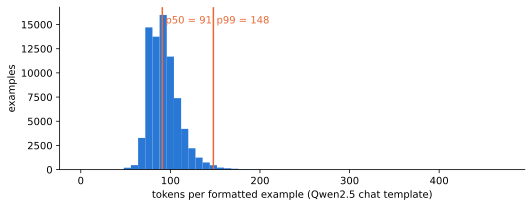

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(total, bins=range(0, int(total.max()) + 8, 8), color="#2a78d6")
for q in [50, 99]:
    v = np.percentile(total, q)
    ax.axvline(v, color="#eb6834", lw=1.5)
    ax.text(v, ax.get_ylim()[1] * 0.9, f" p{q} = {int(v)}", color="#eb6834")
ax.set_xlabel("tokens per formatted example (Qwen2.5 chat template)")
ax.set_ylabel("examples")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. What does the model see?

The model never sees a dictionary; it sees one string in its chat template, broken into tokens. Print one.

In [9]:
ex = examples[int(np.argmin(np.abs(total.values - np.percentile(total, 25))))]
p_ids, a_ids = token_ids(ex)
print(tok.decode(p_ids + a_ids))
print("\nTokens, with the part each belongs to:")
print([(tok.decode([t]), "prompt") for t in p_ids] + [(tok.decode([t]), "answer") for t in a_ids])

<|im_start|>system
You write SQLite queries. Answer with one SQL query and nothing else.<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE candidate_assessments (candidate_id VARCHAR, asessment_outcome_code VARCHAR)

Question: Find id of candidates whose assessment code is "Pass"?<|im_end|>
<|im_start|>assistant
SELECT candidate_id FROM candidate_assessments WHERE asessment_outcome_code = "Pass"<|im_end|>


Tokens, with the part each belongs to:
[('<|im_start|>', 'prompt'), ('system', 'prompt'), ('\n', 'prompt'), ('You', 'prompt'), (' write', 'prompt'), (' SQLite', 'prompt'), (' queries', 'prompt'), ('.', 'prompt'), (' Answer', 'prompt'), (' with', 'prompt'), (' one', 'prompt'), (' SQL', 'prompt'), (' query', 'prompt'), (' and', 'prompt'), (' nothing', 'prompt'), (' else', 'prompt'), ('.', 'prompt'), ('<|im_end|>', 'prompt'), ('\n', 'prompt'), ('<|im_start|>', 'prompt'), ('user', 'prompt'), ('\n', 'prompt'), ('Schema', 'prompt'), (':\n', 'prompt'), ('CREATE', 'prompt'), (' TABLE', 'promp

## 6. Where is the loss computed?

Supervised fine-tuning minimises the negative log-likelihood of the target tokens. Every prompt token can be a target
too, unless it is masked. Measure what each choice trains on: run the untouched model over 256 training examples and
split its loss between prompt tokens and answer tokens.

In [10]:
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map={"": 0}).eval()
sample = random.Random(SEED).sample([e for e, s in zip(examples, clean["split"]) if s == "train"], 256)
loss_prompt = loss_answer = 0.0
n_prompt = n_answer = 0
with torch.inference_mode():
    for ex in sample:
        p_ids, a_ids = token_ids(ex)
        ids = torch.tensor([p_ids + a_ids], device="cuda")
        logits = model(ids).logits[0, :-1].float()
        nll = torch.nn.functional.cross_entropy(logits, ids[0, 1:], reduction="none")
        k = len(p_ids) - 1  # positions predicting a prompt token
        loss_prompt += nll[:k].sum().item(); n_prompt += k
        loss_answer += nll[k:].sum().item(); n_answer += len(a_ids)
print(f"tokens:  prompt {n_prompt / (n_prompt + n_answer):.0%}, answer {n_answer / (n_prompt + n_answer):.0%}")
print(f"loss per token:  prompt {loss_prompt / n_prompt:.2f}, answer {loss_answer / n_answer:.2f}")
print(f"share of an unmasked loss spent on the prompt: {loss_prompt / (loss_prompt + loss_answer):.0%}")

tokens:  prompt 71%, answer 29%
loss per token:  prompt 4.08, answer 0.28
share of an unmasked loss spent on the prompt: 97%


Masking is one line when the labels are built by hand: the prompt positions get the label `-100`, which PyTorch's
cross-entropy ignores. TRL's `SFTTrainer` does the same automatically for data in prompt–completion form, which is
the form saved below.

In [11]:
p_ids, a_ids = token_ids(examples[0])
input_ids = p_ids + a_ids
labels = [-100] * len(p_ids) + a_ids          # -100: no loss on the prompt
print(len(input_ids), "tokens,", sum(l != -100 for l in labels), "of them trained on")

64 tokens, 13 of them trained on


## Save the splits for lesson 4

Each line is one example in conversational prompt–completion form. The files hold only what lesson 4 needs.

In [12]:
for name in ["train", "validation", "test"]:
    part = [e for e, s in zip(examples, clean["split"]) if s == name]
    with open(f"sql_{name}.jsonl", "w") as f:
        for e in part:
            f.write(json.dumps(e) + "\n")
    print(f"sql_{name}.jsonl: {len(part):,} examples")
summary = {"source rows": len(data), "dropped: gold SQL fails": int(data["error"].notna().sum()),
           "dropped: exact duplicates": exact_dupes, "kept": len(clean)}
print(summary)

sql_train.jsonl: 69,170 examples
sql_validation.jsonl: 3,817 examples
sql_test.jsonl: 3,923 examples
{'source rows': 78577, 'dropped: gold SQL fails': 1667, 'dropped: exact duplicates': 0, 'kept': 76910}


## Read the result

- **Check every label you can check for free.** About one gold query in fifty does not run.
- **Split by the unit that repeats.** A random split put most test questions next to a sibling from the same table,
  and a model-free copy baseline scored far higher on it than on a split by table.
- **Size the test set to the claim** you want to make, using its standard error.
- **Write the data in the model's template and train on the answer only:** the prompt is most of the tokens.

The lesson explains each result and the companies that learned the same lessons:
[Prepare the data](https://docs.recohut.com/courses/llm-fine-tuning/1-decide/03-prepare-the-data).